# Session 7: Data Visualisation

**Learning goals:**

- Recognise three common ways to create visualisations in Python: pandas plotting, Matplotlib, and Seaborn.
- Use visualisation as part of exploratory data analysis (EDA).
- Choose charts that suit comparison, distribution, and relationship questions.

**Prerequisites:**

- Introductory pandas skills, including filtering and grouping data.
- Basic understanding of summary statistics.


## Outline

0. **Setup and case context**: load a simple Seaborn example dataset
1. **Visualisation methods in Python**: introduce pandas plotting, Matplotlib, and Seaborn
2. **Exploratory data analysis**: use a short EDA and preparation workflow
3. **Charts for comparison**: apply the methods to category and group comparisons
4. **Charts for distribution**: apply the methods to centre, spread, shape, and unusual values
5. **Charts for relationships**: apply the methods to variables that vary together
6. **Exercises**: practise a question-first visualisation workflow


## 0. Setup and Case Context

This notebook uses Seaborn's simple `tips` example dataset. Each row represents one restaurant bill and records the total bill, tip, dining party size, day, meal time, smoking-area category, and the sex category recorded in the original dataset.

The dataset is useful for learning analytical chart selection because it contains numeric and categorical variables. It is a teaching dataset, so findings should not be generalised to current restaurants or populations.

`sns.load_dataset()` downloads the dataset from the Seaborn data repository the first time it is used and may then use a local cache. An internet connection may therefore be required on the first run.

If a library is missing, run `%pip install pandas matplotlib seaborn` in a new cell and then restart the kernel if requested.


In [1]:
# Import the analysis and visualisation libraries used throughout the notebook.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Apply one readable, colour-blind-friendly style to all Seaborn charts.
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')

# Allow wider tables to display without hiding relevant columns.
pd.set_option('display.max_columns', 20)

Load the `tips` dataset directly through Seaborn.


In [2]:
# Load a simple example dataset maintained for Seaborn tutorials.
tips = sns.load_dataset('tips')  # Return the example data as a pandas DataFrame.

print('Rows and columns:', tips.shape)  # Check the dataset dimensions.
tips.head()  # Preview the first five observations and their variables.

Rows and columns: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### Data dictionary

| Variable | Meaning in the example dataset | Type |
| --- | --- | --- |
| `total_bill` | total restaurant bill in US dollars | numeric |
| `tip` | tip amount in US dollars | numeric |
| `sex` | category recorded in the source dataset | categorical |
| `smoker` | whether the party was in the smoking category | categorical |
| `day` | abbreviated day of the week | categorical |
| `time` | lunch or dinner | categorical |
| `size` | number of people in the dining party | numeric count |

The category labels describe how the example data was recorded; they should not be interpreted as complete or universally appropriate demographic definitions.


## 1. Visualisation Methods in Python

Python offers several connected ways to create charts. This notebook uses three common approaches:

| Method | Starting point | Main advantage | Typical analytical use |
| --- | --- | --- | --- |
| pandas `.plot()` | a `Series` or `DataFrame` | quick chart from a table or summary | rapid EDA after grouping or reshaping |
| Matplotlib | a figure and one or more axes | detailed control over chart components | customised layouts, labels, annotations, and publication-ready views |
| Seaborn | tidy data with named variables | concise statistical graphics and grouping | comparisons, distributions, relationships, and uncertainty |

These are not separate systems. Pandas and Seaborn both create charts using Matplotlib underneath, so the same Matplotlib axes can often be refined after the chart is created.

Official learning resources:

- [Matplotlib tutorials](https://matplotlib.org/stable/tutorials/index.html)
- [Seaborn tutorial](https://seaborn.pydata.org/tutorial.html)


### 1.1 Pandas plotting

Pandas plotting is convenient when the required data is already in a `Series` or `DataFrame`. The usual pattern is:

1. select or summarise the data
2. call `.plot()`
3. add a clear title and axis labels

The example below compares median bill values across days. The analytical summary is calculated before the chart is created.


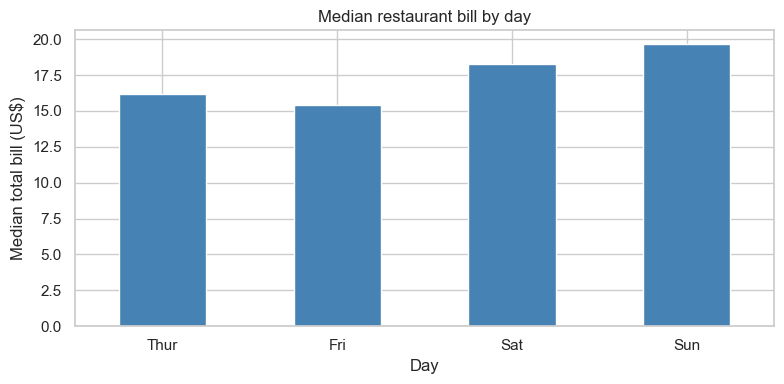

In [3]:
# Create a summary table, then plot it directly with pandas.
day_order = ['Thur', 'Fri', 'Sat', 'Sun']
intro_day_summary = (
    tips.groupby('day', observed=True)['total_bill']  # Split bills into observed day groups.
    .median()                                             # Calculate a robust typical bill per day.
    .reindex(day_order)                                   # Restore the intended day sequence.
)

ax = intro_day_summary.plot(
    kind='bar',          # Display one vertical bar for each day.
    figsize=(8, 4),      # Set the figure size to 8 inches wide and 4 inches high.
    color='steelblue',   # Use a named colour for all bars.
)
ax.set(
    title='Median restaurant bill by day',
    xlabel='Day',
    ylabel='Median total bill (US$)',
)
ax.set_ylim(bottom=0)       # Use a zero baseline so bar lengths are not exaggerated.
plt.xticks(rotation=0)       # Keep the short day labels horizontal.
plt.tight_layout()           # Prevent titles and labels from being clipped.
plt.show()

Pandas plotting is effective for a fast first view. It is less convenient when a chart needs several layers, multiple panels, or detailed control over individual elements.

### 1.2 Matplotlib

Matplotlib organises a chart around two main objects:

- the **figure**, which is the full drawing area
- an **axes**, which is one chart or panel inside the figure

`plt.subplots()` creates both objects. Methods such as `ax.hist()`, `ax.set()`, and `ax.axvline()` then add or refine chart elements.


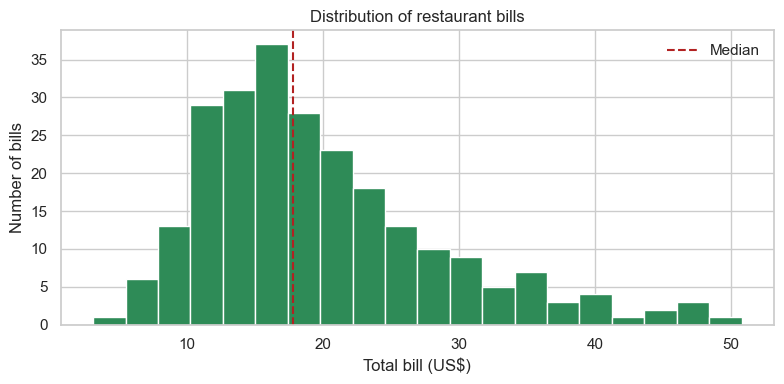

In [4]:
# Create a histogram directly with Matplotlib's axes methods.
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(
    tips['total_bill'],
    bins=20,             # Divide bill values into 20 equal-width intervals.
    color='seagreen',    # Use a named fill colour.
    edgecolor='white',   # Separate neighbouring bins visually.
)
ax.axvline(
    tips['total_bill'].median(),  # Place the reference at the sample median.
    color='firebrick',
    linestyle='--',
    label='Median',
)
ax.set(
    title='Distribution of restaurant bills',
    xlabel='Total bill (US$)',
    ylabel='Number of bills',
)
ax.legend(frameon=False)  # Explain the reference line without a legend border.
plt.tight_layout()        # Fit labels inside the figure boundary.
plt.show()

Matplotlib requires more explicit instructions, but those instructions provide control over axes, scales, annotations, legends, and multi-panel layouts.

### 1.3 Seaborn

Seaborn works especially well with tidy data: each row is an observation, each column is a variable, and each cell is a value. Variables are mapped to visual features by name, such as:

- `x` and `y` for position
- `hue` for colour groups
- `style` for marker groups
- `size` for marker size

The example below maps bill amount, tip amount, and meal time directly from the `tips` DataFrame.


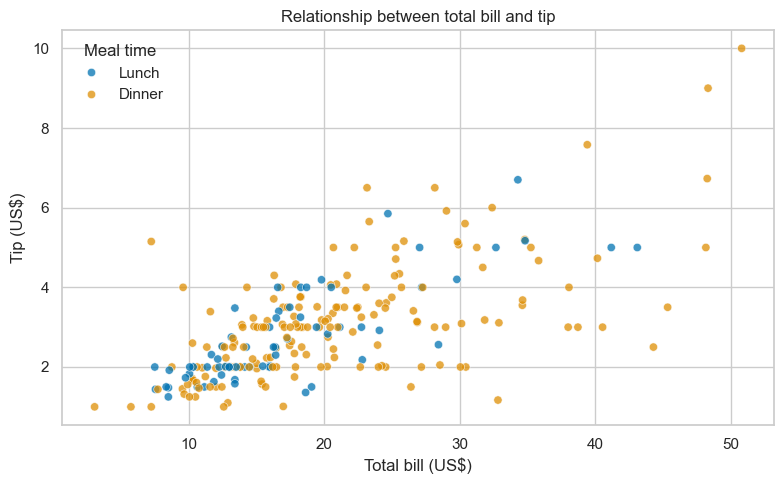

In [5]:
# Map named DataFrame variables to visual features with Seaborn.
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=tips,             # Use named columns from the tips DataFrame.
    x='total_bill',        # Map bill amount to horizontal position.
    y='tip',               # Map tip amount to vertical position.
    hue='time',            # Use colour to distinguish lunch and dinner.
    palette='colorblind',  # Select colours from a readable Seaborn palette.
    alpha=0.75,            # Make overlapping observations easier to see.
    ax=ax,                 # Draw on the Matplotlib axes created above.
)
ax.set(
    title='Relationship between total bill and tip',
    xlabel='Total bill (US$)',
    ylabel='Tip (US$)',
)
ax.legend(title='Meal time', frameon=False)
plt.tight_layout()
plt.show()

Seaborn reduces the code needed for grouped statistical charts. Matplotlib remains available through `fig` and `ax`, so the result can still be customised.

### 1.4 Choosing and combining the methods

| Situation | Useful starting method |
| --- | --- |
| a grouped pandas summary needs a quick chart | pandas `.plot()` |
| exact control over every element is required | Matplotlib |
| the chart maps several DataFrame variables or shows a statistical distribution | Seaborn |
| a dashboard or multi-panel figure combines several chart types | Matplotlib layout with pandas or Seaborn charts |

The next example combines a summary and the underlying distribution. Seaborn creates both panels, while Matplotlib controls the layout, titles, and axes.


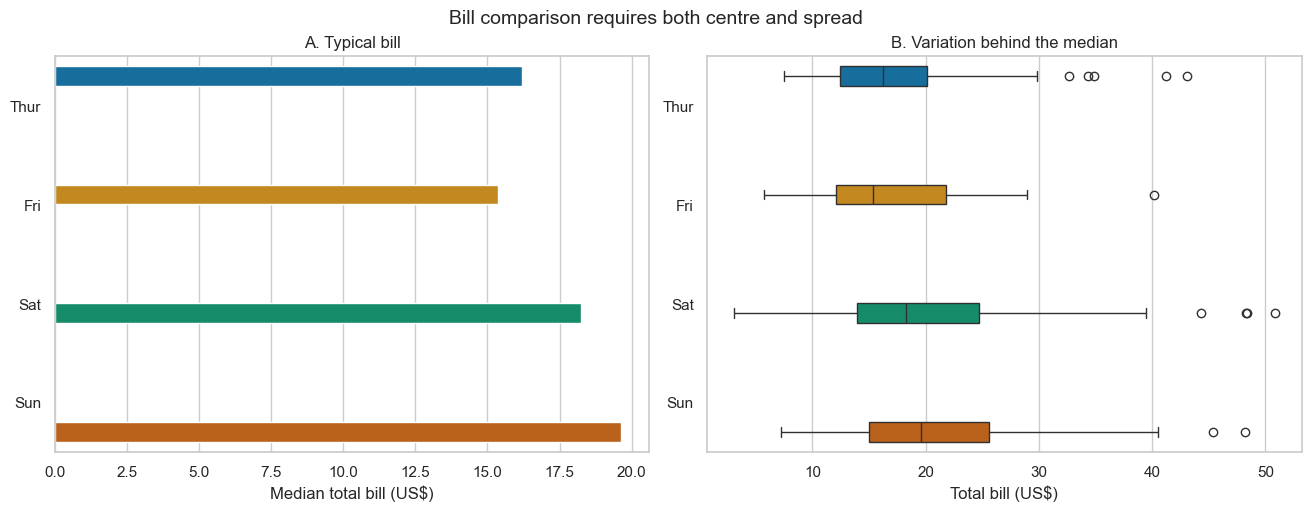

In [6]:
# Combine a summary view with the underlying distribution.
intro_day_table = (
    tips.groupby('day', observed=True, as_index=False)  # Keep day as a normal column.
    .agg(median_bill=('total_bill', 'median'))           # Name the plotted summary explicitly.
)

# Create one row with two axes so the summary and distribution can be compared.
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

sns.barplot(
    data=intro_day_table,
    x='median_bill',  # Encode the summary value as bar length.
    y='day',          # Place one bar on each day category.
    order=day_order,  # Keep the same meaningful day sequence.
    hue='day',
    legend=False,
    palette='colorblind',
    ax=axes[0],
)
axes[0].set(
    title='A. Typical bill',
    xlabel='Median total bill (US$)',
    ylabel='',
)
axes[0].set_xlim(left=0)

sns.boxplot(
    data=tips,
    x='total_bill',  # Show the individual bill distribution horizontally.
    y='day',         # Create one box for each day.
    order=day_order, # Match the category order in the left panel.
    hue='day',
    legend=False,
    palette='colorblind',
    ax=axes[1],
)
axes[1].set(
    title='B. Variation behind the median',
    xlabel='Total bill (US$)',
    ylabel='',
)

fig.suptitle('Bill comparison requires both centre and spread', fontsize=14)
plt.show()

### 1.5 Refining a chart for communication

Refinement is not decoration. Useful refinements make the question, measure, scale, groups, and uncertainty easier to understand.

Before sharing a chart, check that it has:

- a title stating the analytical message or question
- units in axis labels, including currency or percentages
- a sensible category order
- readable labels and a restrained, colour-blind-friendly palette
- a zero baseline for bar lengths
- enough context to identify the population and dataset limitations
- no unnecessary three-dimensional effects, dual axes, or decorative clutter

Direct value labels can reduce the effort needed to read a focused comparison.


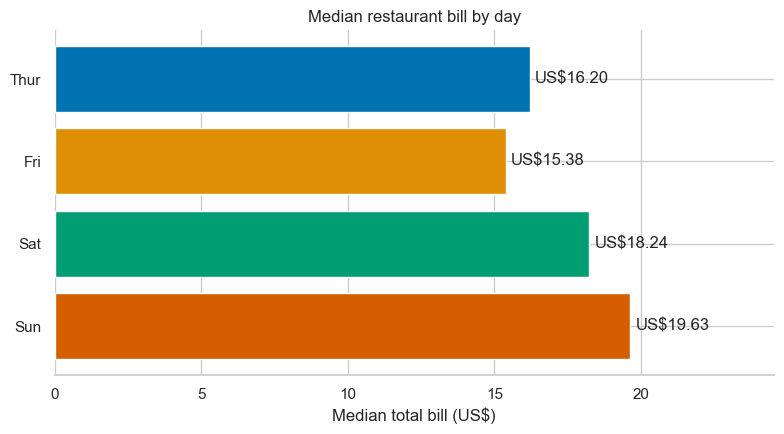

In [7]:
# Use Matplotlib to add direct labels to a focused comparison.
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(
    intro_day_summary.index.astype(str),  # Use day labels on the categorical axis.
    intro_day_summary.values,             # Use median bills as bar lengths.
    color=sns.color_palette(
        'colorblind', len(intro_day_summary)  # Select one palette colour per day.
    ),
)
ax.invert_yaxis()  # Place the first day at the top of the chart.
ax.bar_label(bars, fmt='US$%.2f', padding=4)  # Label each bar with its exact median.
ax.set(
    title='Median restaurant bill by day',
    xlabel='Median total bill (US$)',
    ylabel='',
)

# Add right-side space so direct labels remain inside the plotting area.
ax.set_xlim(0, intro_day_summary.max() * 1.25)
sns.despine(ax=ax, left=True)  # Remove non-essential chart borders.
plt.tight_layout()
plt.show()

## 2. Exploratory Data Analysis

After learning how the three Python methods create charts, the next step is to use them within an analytical process.

EDA is a structured investigation of a dataset before formal modelling or decision-making. It helps an analyst:

- understand what one row represents and how variables are measured
- identify missing values, errors, unusual observations, and imbalanced groups
- compare categories and examine distributions
- investigate relationships between variables
- generate questions and decide what needs further validation

Visualisation complements data definitions, preparation checks, and numerical summaries; it does not replace them.


### A question-first EDA workflow

| Step | Analytical decision | Example using `tips` |
| --- | --- | --- |
| 1. Ask | State a specific question | Does typical tip percentage differ by day? |
| 2. Prepare | Check structure, missing values, units, and group sizes | Is each row one bill? Are values missing? |
| 3. Summarise | Match the calculation to the question | Calculate median tip percentage by day |
| 4. Visualise | Choose an encoding that supports comparison | Use a bar, dot, or box plot |
| 5. Interpret | Describe evidence, context, and uncertainty | Report the pattern without claiming causation |
| 6. Validate | Test whether the finding is robust | Inspect distributions and group sizes |

Useful interpretation language separates three ideas:

- **Observation:** what is visible or calculated
- **Possible explanation:** what might produce the pattern
- **Next check:** what evidence would test that explanation


### A short preparation check

Preparation for visualisation should be proportionate to the question. Before plotting, confirm:

- what one row represents
- whether data types and units are appropriate
- whether important values are missing
- whether groups have enough observations
- whether unusual values are valid, exceptional, or incorrect

The following compact check covers structure, missing values, group size, and numeric summaries.


In [8]:
# Run a compact preparation check before visual analysis.
print('Rows and columns:', tips.shape)
display(pd.DataFrame({
    'dtype': tips.dtypes.astype(str),                 # Confirm how each variable is stored.
    'missing_values': tips.isna().sum(),              # Count unavailable observations.
    'distinct_values': tips.nunique(dropna=True),     # Check category levels and numeric variety.
}))
# Check whether day groups have very different sample sizes.
display(tips['day'].value_counts(sort=False).rename('bill_count').to_frame())

# Transpose the numeric summary so one variable appears on each row.
display(tips[['total_bill', 'tip', 'size']].describe().T)

Rows and columns: (244, 7)


,dtype,missing_values,distinct_values
total_bill,float64,0,229
tip,float64,0,123
sex,category,0,2
smoker,category,0,2
day,category,0,4
time,category,0,2
size,int64,0,6


,bill_count
day,
Thur,62
Fri,19
Sat,87
Sun,76


,count,mean,std,min,25%,50%,75%,max
total_bill,244.0,19.785943,8.902412,3.07,13.3475,17.795,24.1275,50.81
tip,244.0,2.998279,1.383638,1.00,2.0000,2.900,3.5625,10.00
size,244.0,2.569672,0.951100,1.00,2.0000,2.000,3.0000,6.00


Create derived measures only when their definitions support the question. Tip amount is affected by bill size, so tip percentage provides a rate for comparison:

**tip percentage = tip ÷ total bill × 100**

The original `tips` DataFrame remains unchanged. Extreme values are retained for visual investigation rather than removed automatically.


In [9]:
# Create an analysis table and a transparent derived measure.
analysis = tips.copy()  # Preserve the source DataFrame for later auditing.

# Standardise tip amount by bill size and express the result as a percentage.
analysis['tip_percentage'] = analysis['tip'] / analysis['total_bill'] * 100

analysis[['total_bill', 'tip', 'tip_percentage', 'size']].describe().T

,count,mean,std,min,25%,50%,75%,max
total_bill,244.0,19.785943,8.902412,3.070000,13.347500,17.795000,24.127500,50.810000
tip,244.0,2.998279,1.383638,1.000000,2.000000,2.900000,3.562500,10.000000
tip_percentage,244.0,16.080258,6.107220,3.563814,12.912736,15.476977,19.147549,71.034483
size,244.0,2.569672,0.951100,1.000000,2.000000,2.000000,3.000000,6.000000


### Match the chart to the analytical question

| Question type | What the analyst wants to know | Common chart choices |
| --- | --- | --- |
| Comparison | Which category is larger or smaller? | bar chart, dot plot |
| Distribution | What values are typical, variable, skewed, or unusual? | histogram, density plot, box plot |
| Relationship | Do two measures vary together, and does the pattern differ by group? | scatter plot, regression view, heatmap |

The following sections apply pandas, Matplotlib, and Seaborn to these three types of analytical question.


## 3. Charts for Comparison

Comparison charts require a clear denominator and level of aggregation.

| Analytical question | Useful measure | Suitable chart | Important check |
| --- | --- | --- | --- |
| Which day has the largest typical bill? | median total bill | sorted bar or dot plot | bill count and party size |
| Which day has the strongest typical tipping rate? | median tip percentage | bar or dot plot | spread and group size |
| Do lunch and dinner differ by day? | day–time summary | grouped bars or small multiples | missing combinations |

### Question: Does median tip percentage differ by day?


In [10]:
# Calculate an explicit day-level summary before plotting.
day_summary = (
    analysis.groupby('day', observed=True, as_index=False)  # Create one summary row per day.
    .agg(
        bills=('total_bill', 'size'),                         # Retain the evidence count.
        median_bill=('total_bill', 'median'),                 # Summarise typical bill size.
        median_tip_percentage=('tip_percentage', 'median'),   # Summarise typical tipping rate.
    )
)
# Store day as an ordered category so sorting follows the intended sequence.
day_summary['day'] = pd.Categorical(
    day_summary['day'], categories=day_order, ordered=True
)
day_summary = day_summary.sort_values('day')

day_summary

,day,bills,median_bill,median_tip_percentage
0,Thur,62,16.20,15.384615
1,Fri,19,15.38,15.562472
2,Sat,87,18.24,15.183246
3,Sun,76,19.63,16.110332


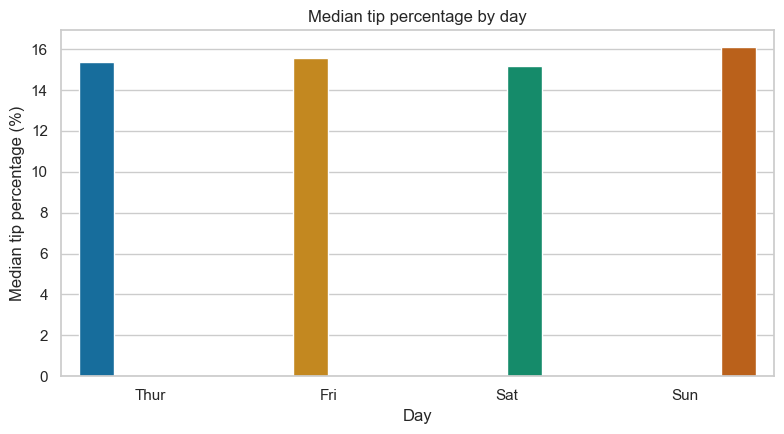

In [11]:
# Use Seaborn to compare the pre-calculated medians.
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(
    data=day_summary,
    x='day',                    # Place day categories along the horizontal axis.
    y='median_tip_percentage',  # Encode the pre-calculated median as bar height.
    hue='day',                  # Assign a palette colour to each day.
    legend=False,               # Axis labels already identify the day groups.
    palette='colorblind',
    ax=ax,
)
ax.set(
    title='Median tip percentage by day',
    xlabel='Day',
    ylabel='Median tip percentage (%)',
)
ax.set_ylim(bottom=0)  # Start bar heights at zero for an honest comparison.
plt.tight_layout()
plt.show()

The bars make the medians easy to compare, while the summary table retains bill counts. Small median differences may not be practically important. Inspect the underlying distributions before making a recommendation.

### Question: Does the day comparison differ between lunch and dinner?


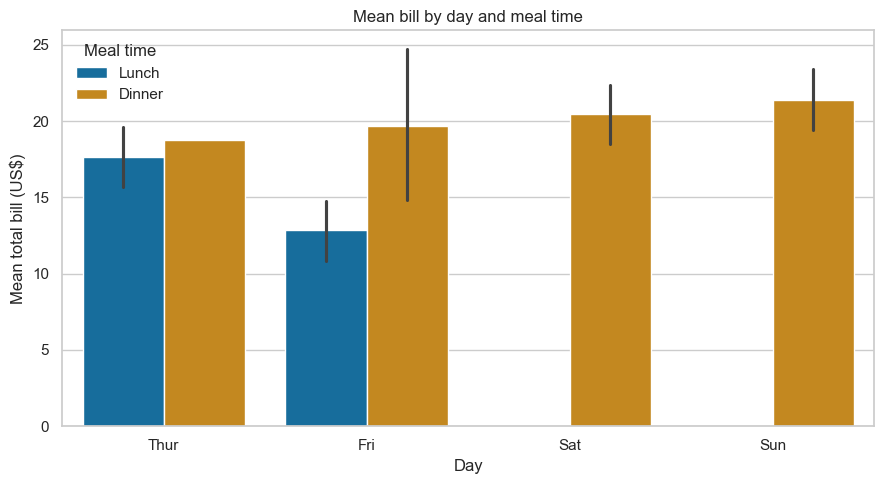

In [12]:
# Compare mean bill values for observed day–meal combinations.
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=analysis,
    x='day',                # Compare day categories.
    y='total_bill',         # Summarise bill values on the vertical axis.
    hue='time',             # Place lunch and dinner bars side by side.
    order=day_order,        # Preserve the intended day sequence.
    estimator='mean',       # Plot the sample mean for each observed group.
    errorbar=('ci', 95),    # Add a bootstrap 95% confidence interval.
    palette='colorblind',
    ax=ax,
)
ax.set(
    title='Mean bill by day and meal time',
    xlabel='Day',
    ylabel='Mean total bill (US$)',
)
ax.set_ylim(bottom=0)
ax.legend(title='Meal time', frameon=False)
plt.tight_layout()
plt.show()

The uncertainty intervals show that estimates from a sample are not exact. Some day–meal combinations do not occur in this dataset, so blank combinations should not be interpreted as zero bills.


## 4. Charts for Distribution

A single average does not show variability, skew, multiple clusters, or unusual values. Distribution charts help answer questions such as:

- What is a typical result?
- How consistent are the values?
- Is the distribution symmetric or skewed?
- Are there observations that need investigation?

### Question: What does the full distribution of total bills look like?


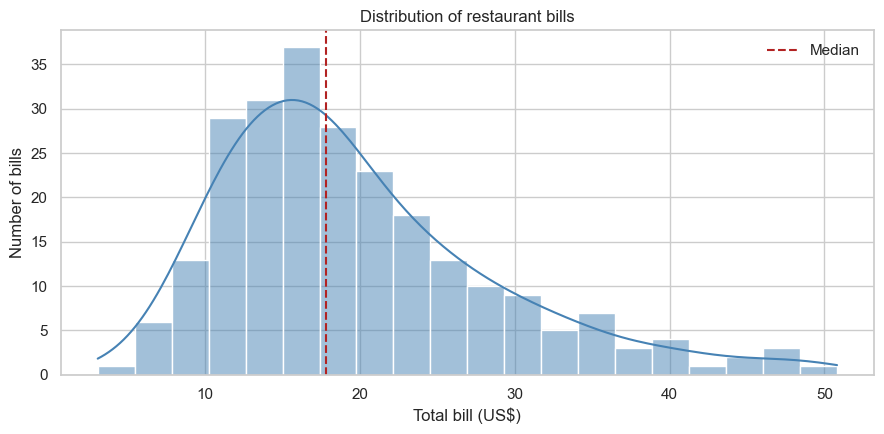

In [13]:
# Combine a histogram with a smoothed density estimate.
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(
    data=analysis,
    x='total_bill',    # Analyse the distribution of bill values.
    bins=20,           # Control the histogram interval width through the bin count.
    kde=True,          # Overlay a smoothed density estimate for overall shape.
    color='steelblue',
    ax=ax,
)
ax.axvline(
    analysis['total_bill'].median(),  # Mark a robust measure of centre.
    color='firebrick',
    linestyle='--',
    label='Median',
)
ax.set(
    title='Distribution of restaurant bills',
    xlabel='Total bill (US$)',
    ylabel='Number of bills',
)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

The histogram shows the frequency of bill ranges, while the density curve provides a smoothed view of shape. Both depend on display settings, so use them to understand structure rather than to claim an exact boundary.

### Question: Which days have consistent or variable tip percentages?


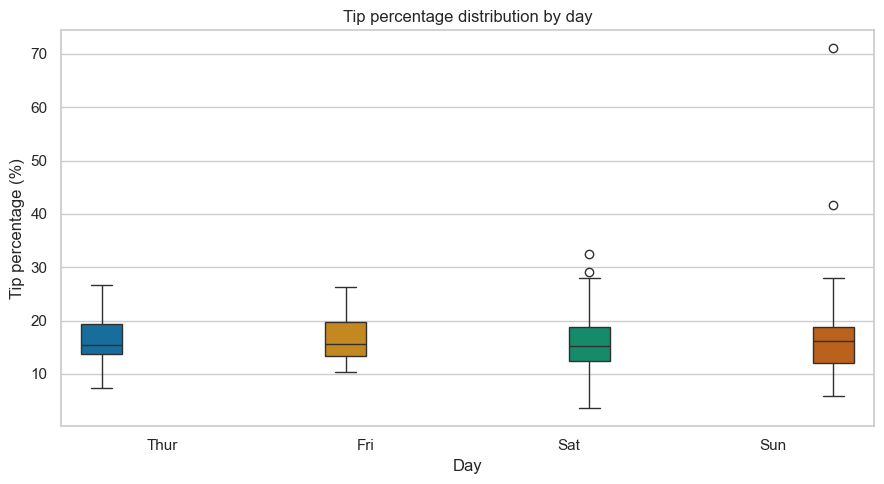

In [14]:
# Compare medians, interquartile ranges, and unusual values across days.
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(
    data=analysis,
    x='day',             # Create one distribution for each day.
    y='tip_percentage',  # Compare the rate rather than the raw tip amount.
    order=day_order,     # Keep the day sequence consistent across charts.
    hue='day',           # Apply one palette colour per box.
    legend=False,        # The x-axis already identifies each group.
    palette='colorblind',
    ax=ax,
)
ax.set(
    title='Tip percentage distribution by day',
    xlabel='Day',
    ylabel='Tip percentage (%)',
)
plt.tight_layout()
plt.show()

In a box plot, the centre line is the median, the box covers the middle 50% of values, and the whiskers show the typical range under the plotting rule. Points beyond the whiskers are not automatically errors. Investigate their context before deciding whether they are valid, exceptional, or incorrect.


## 5. Charts for Relationships

Relationship charts investigate whether variables vary together. The visual pattern may be positive, negative, non-linear, clustered, or dominated by unusual observations.

### Question: Are larger bills associated with larger tips?


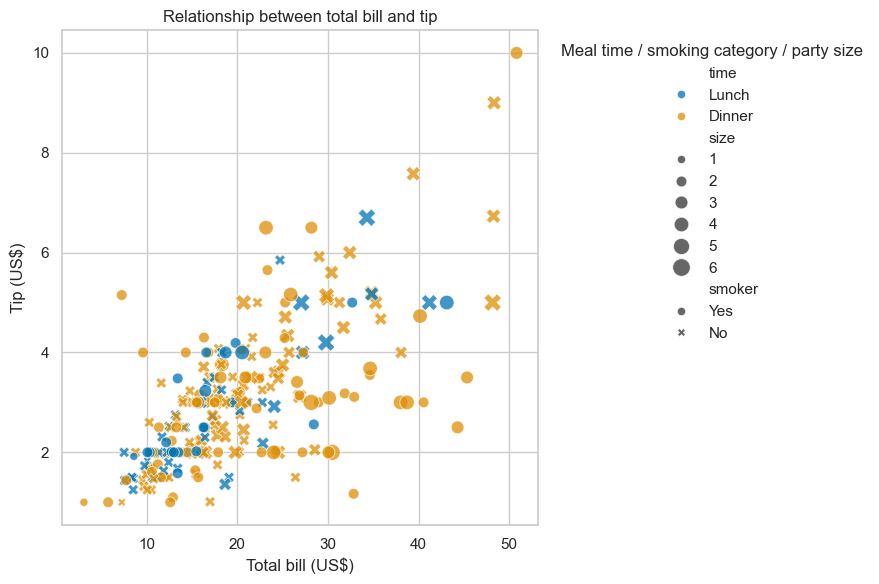

In [15]:
# Show individual bills and distinguish meal-time groups.
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=analysis,
    x='total_bill',   # Map bill amount to horizontal position.
    y='tip',          # Map tip amount to vertical position.
    hue='time',       # Distinguish meal times with colour.
    style='smoker',   # Distinguish smoking categories with marker shapes.
    size='size',      # Represent dining party size through marker area.
    sizes=(35, 160),  # Keep the smallest and largest markers readable.
    alpha=0.75,       # Reveal overlapping observations.
    palette='colorblind',
    ax=ax,
)
ax.set(
    title='Relationship between total bill and tip',
    xlabel='Total bill (US$)',
    ylabel='Tip (US$)',
)
# Move the multi-part legend outside so it does not cover observations.
ax.legend(
    title='Meal time / smoking category / party size',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=False,
)
plt.tight_layout()
plt.show()

The scatter plot shows a positive association, but also considerable variation between bills of similar size. Because the dataset is observational, the chart does not establish that increasing a bill causes a predictable increase in its tip. Service, group characteristics, venue practices, and unrecorded context may matter.

### Add a fitted summary cautiously


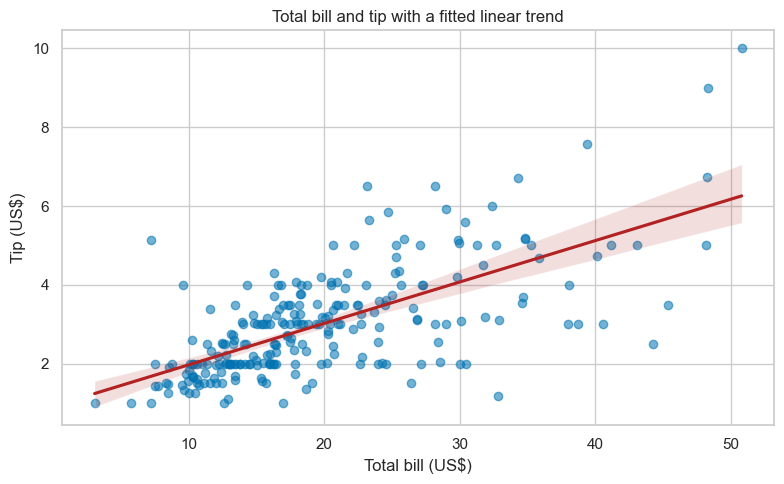

In [16]:
# Add a simple fitted line while retaining the observed points.
fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(
    data=analysis,
    x='total_bill',
    y='tip',
    scatter_kws={'alpha': 0.55},        # Reduce overplotting among observations.
    line_kws={'color': 'firebrick'},  # Emphasise the fitted trend with a named colour.
    ax=ax,
)
ax.set(
    title='Total bill and tip with a fitted linear trend',
    xlabel='Total bill (US$)',
    ylabel='Tip (US$)',
)
plt.tight_layout()
plt.show()

The line summarises the average linear pattern; it is not a prediction rule for every bill. Always inspect the points because a fitted line can hide spread, clusters, non-linearity, and influential observations.

### Question: Which numeric measures move together?

A correlation heatmap is a compact screening view. It should be followed by direct plots because correlation can hide non-linearity, groups, and influential observations.


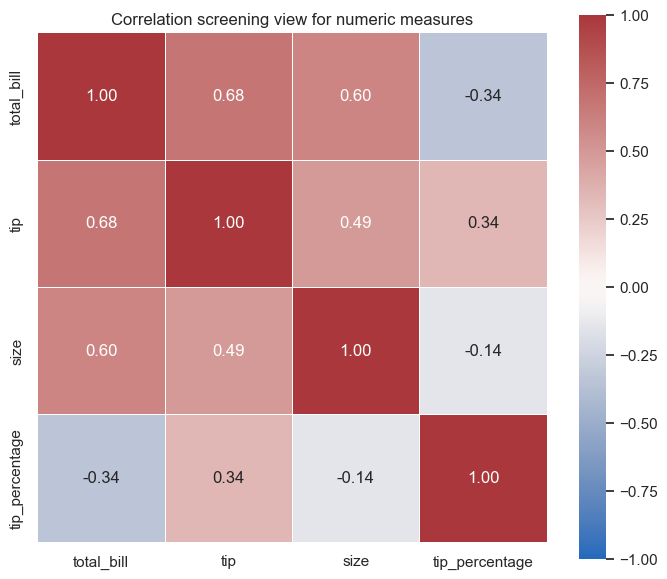

In [17]:
# Calculate and plot pairwise Pearson correlations for numeric measures.
# Limit the calculation to numeric measures relevant to the question.
correlation_columns = ['total_bill', 'tip', 'size', 'tip_percentage']
correlations = analysis[correlation_columns].corr()  # Pearson correlation is the default.

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    correlations,
    cmap='vlag',    # Use a diverging Seaborn colour map.
    center=0,       # Give zero correlation the neutral midpoint colour.
    vmin=-1,        # Fix the correlation scale at its theoretical minimum.
    vmax=1,         # Fix the correlation scale at its theoretical maximum.
    annot=True,     # Print the coefficient inside each cell.
    fmt='.2f',      # Display coefficients to two decimal places.
    square=True,    # Draw equal-height and equal-width cells.
    linewidths=0.5,
    ax=ax,
)
ax.set_title('Correlation screening view for numeric measures')
plt.tight_layout()
plt.show()

Tip percentage is calculated from tip and total bill, so these measures are mechanically connected. A correlation involving derived variables is not an independent discovery. Interpret the heatmap using the definitions and collection context.


## 6. Exercises

Use this sequence for each task:

1. write the analytical question in one sentence
2. calculate the required summary or quality check
3. choose a chart and explain why it fits
4. create the chart
5. record one observation, one possible explanation, and one next check

### Exercise 1: Comparison

Compare median total bill across meal time and smoking-area category. Create an appropriate comparison chart. State why medians are useful here and report the number of bills in each group.


In [18]:
# Exercise 1 scaffold
meal_smoker_summary = (
    analysis.groupby(['time', 'smoker'], observed=True, as_index=False)  # Form observed two-way groups.
    .agg(
        bills=('total_bill', 'size'),          # Count the evidence behind each result.
        median_bill=('total_bill', 'median'),  # Calculate a robust typical bill.
    )
)

# Create a grouped comparison chart with units and a zero baseline.
meal_smoker_summary

,time,smoker,bills,median_bill
0,Lunch,Yes,23,16.000
1,Lunch,No,45,15.950
2,Dinner,Yes,70,20.695
3,Dinner,No,106,18.265


#### Exercise 1 worked solution

Grouped bars support comparison within each meal time. The median reduces the influence of the largest bills, while the group counts show how much evidence supports each bar.


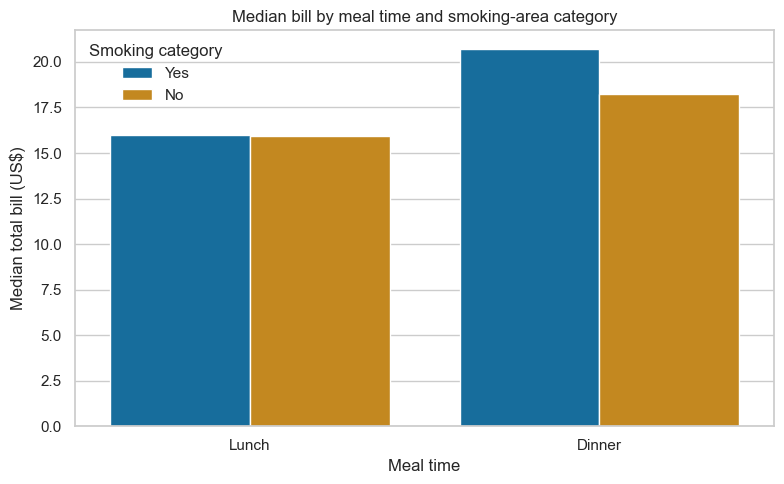

In [19]:
# Worked solution: compare median bills by meal time and smoking category.
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=meal_smoker_summary,
    x='time',          # Compare meal-time categories.
    y='median_bill',   # Plot the pre-calculated median bill.
    hue='smoker',      # Place smoking categories side by side.
    palette='colorblind',
    ax=ax,
)
ax.set(
    title='Median bill by meal time and smoking-area category',
    xlabel='Meal time',
    ylabel='Median total bill (US$)',
)
ax.set_ylim(bottom=0)
ax.legend(title='Smoking category', frameon=False)
plt.tight_layout()
plt.show()

### Exercise 2: Distribution

Compare tip percentage distributions for lunch and dinner. Use a box plot and a table containing group size, median, Q1, Q3, and IQR. Which meal time appears more variable? What would you check before explaining the difference?


In [20]:
# Exercise 2 scaffold
# 1. Group by time and calculate count, median, Q1, and Q3.
# 2. Calculate IQR as Q3 minus Q1.
# 3. Create a box plot of tip_percentage by time.
analysis[['time', 'tip_percentage']].head()  # Preview only the variables needed for the task.

,time,tip_percentage
0,Dinner,5.944673
1,Dinner,16.054159
2,Dinner,16.658734
3,Dinner,13.978041
4,Dinner,14.680765


#### Exercise 2 worked solution

Variability can be compared using the IQR, but a larger IQR does not explain why the groups differ. Check bill size, party size, day mix, and group counts before proposing an explanation.


,bills,median,q1,q3,iqr
time,,,,,
Lunch,68,15.408357,13.914666,19.391734,5.477068
Dinner,176,15.540002,12.319151,18.820878,6.501727


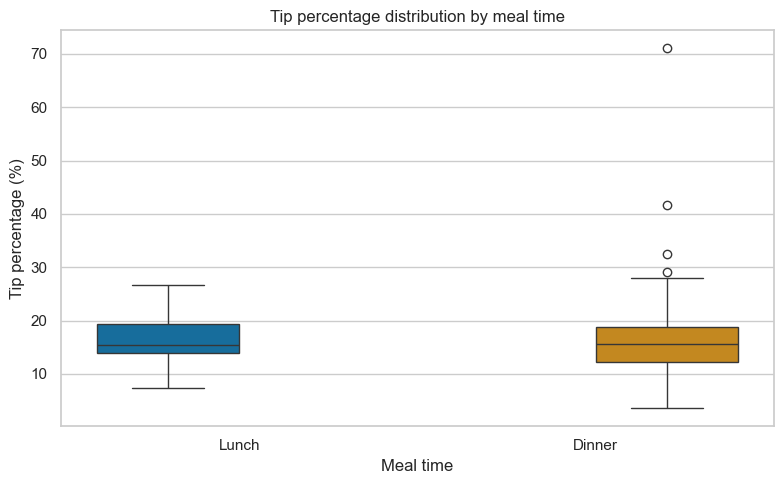

In [21]:
# Worked solution: summarise and visualise the meal-time distributions.
time_distribution = (
    analysis.groupby('time', observed=True)['tip_percentage']
    .agg(
        bills='size',                                      # Count bills in each meal-time group.
        median='median',                                   # Measure the centre robustly.
        q1=lambda values: values.quantile(0.25),           # Calculate the lower quartile.
        q3=lambda values: values.quantile(0.75),           # Calculate the upper quartile.
    )
)
# Measure the spread of the middle 50% of tip percentages.
time_distribution['iqr'] = time_distribution['q3'] - time_distribution['q1']
display(time_distribution.sort_values('iqr'))

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=analysis,
    x='time',            # Draw one box for lunch and one for dinner.
    y='tip_percentage',  # Compare the derived tipping rate.
    hue='time',          # Apply a palette colour to each meal time.
    legend=False,        # The x-axis already identifies the groups.
    palette='colorblind',
    ax=ax,
)
ax.set(
    title='Tip percentage distribution by meal time',
    xlabel='Meal time',
    ylabel='Tip percentage (%)',
)
plt.tight_layout()
plt.show()

### Exercise 3: Relationship within groups

Investigate the total bill–tip relationship separately for lunch and dinner. Use small multiples with common axis scales. Explain why separate views can be more informative than one overall fitted line.


In [22]:
# Exercise 3 scaffold
# Use sns.lmplot() with x='total_bill', y='tip', and col='time'.
# Keep common x and y scales so the panels remain comparable.
analysis[['time', 'total_bill', 'tip']].head()  # Preview the grouping, x, and y variables.

,time,total_bill,tip
0,Dinner,16.99,1.01
1,Dinner,10.34,1.66
2,Dinner,21.01,3.50
3,Dinner,23.68,3.31
4,Dinner,24.59,3.61


#### Exercise 3 worked solution

Small multiples reduce overlap and make within-group form and spread visible. They help show whether the overall relationship is broadly shared or is dominated by one meal-time group.


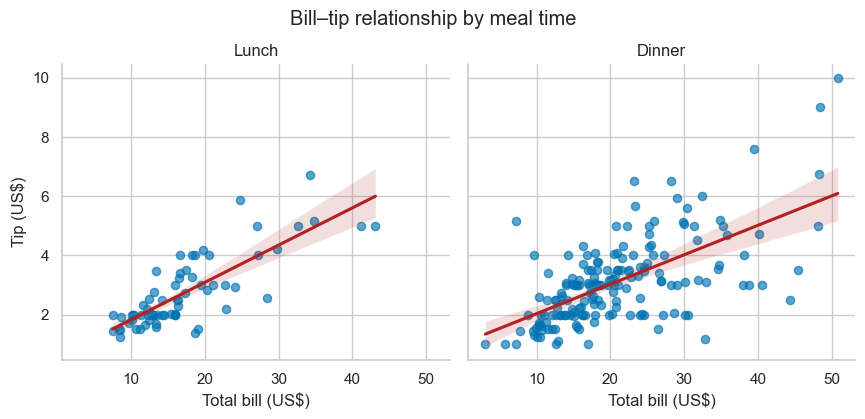

In [23]:
# Worked solution: compare within-group relationships using common scales.
relationship_grid = sns.lmplot(
    data=analysis,
    x='total_bill',   # Use bill amount as the explanatory axis.
    y='tip',          # Use tip amount as the response axis.
    col='time',       # Create one panel for each meal time.
    height=4,         # Set the height of each panel in inches.
    aspect=1.1,       # Make each panel slightly wider than it is high.
    scatter_kws={'alpha': 0.65, 's': 35},  # Keep overlapping points visible.
    line_kws={'color': 'firebrick'},        # Use a named colour for fitted lines.
    facet_kws={
        'sharex': True,  # Use common bill limits for valid panel comparison.
        'sharey': True,  # Use common tip limits for valid panel comparison.
    },
)
relationship_grid.set_axis_labels('Total bill (US$)', 'Tip (US$)')
relationship_grid.set_titles('{col_name}')
relationship_grid.figure.suptitle('Bill–tip relationship by meal time', y=1.04)
plt.show()